### 1. Setup


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="darkgrid", context="notebook", palette="mako")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Collects the final answer of each question, printed in the summary at the end
answers = {}

### 2. Load & clean the data

In [3]:
DATA_PATH = "fastfood.csv"

df_raw = pd.read_csv("fastfood.csv")
print("Loaded:", "fastfood.csv", "| shape:", df_raw.shape)
df_raw.head()

Loaded: fastfood.csv | shape: (515, 17)


,restaurant,item,calories,cal_fat,total_fat,sat_fat,trans_fat,cholesterol,sodium,total_carb,fiber,sugar,protein,vit_a,vit_c,calcium,salad
0,Mcdonalds,Artisan Grilled Chicken Sandwich,380,60,7,2.00,0.00,95,1110,44,3.00,11,37.00,4.00,20.00,20.00,Other
1,Mcdonalds,Single Bacon Smokehouse Burger,840,410,45,17.00,1.50,130,1580,62,2.00,18,46.00,6.00,20.00,20.00,Other
2,Mcdonalds,Double Bacon Smokehouse Burger,1130,600,67,27.00,3.00,220,1920,63,3.00,18,70.00,10.00,20.00,50.00,Other
3,Mcdonalds,Grilled Bacon Smokehouse Chicken Sandwich,750,280,31,10.00,0.50,155,1940,62,2.00,18,55.00,6.00,25.00,20.00,Other
4,Mcdonalds,Crispy Bacon Smokehouse Chicken Sandwich,920,410,45,12.00,0.50,120,1980,81,4.00,18,46.00,6.00,20.00,20.00,Other


In [4]:
df = df_raw.copy()

# Standardise column names and drop any leftover index column
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
df = df.loc[:, ~df.columns.str.startswith("unnamed")]

# Strip whitespace in text columns
for c in ["restaurant", "item", "salad"]:
    df[c] = df[c].astype(str).str.strip()

required = ["restaurant","item","calories","cal_fat","total_fat","sat_fat","trans_fat","cholesterol",
            "sodium","total_carb","fiber","sugar","protein","vit_a","vit_c","calcium","salad"]
missing_cols = [c for c in required if c not in df.columns]
assert not missing_cols, f"Missing expected columns: {missing_cols}"

# Remove exact duplicate rows
n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Exact duplicate rows removed: {n_dup}")

# Simple, readable food-type flag for Q7
print("Values in the 'salad' column:", df["salad"].value_counts(dropna=False).to_dict())
_s = df["salad"].str.lower()
is_salad = _s.str.contains("salad") | _s.isin(["yes", "y", "true", "1", "1.0"])
if is_salad.sum() == 0:
    # The flag has no usable 'Salad' value, so fall back to the item name
    is_salad = df["item"].str.lower().str.contains("salad")
    print("No salad flag found in the 'salad' column: using item names containing 'salad' instead.")
df["food_type"] = np.where(is_salad, "Salad", "Other")
print("food_type counts:", df["food_type"].value_counts().to_dict())

num_cols = ["calories","cal_fat","total_fat","sat_fat","trans_fat","cholesterol","sodium",
            "total_carb","fiber","sugar","protein","vit_a","vit_c","calcium"]
print("Final shape:", df.shape)
df.head()

Exact duplicate rows removed: 2
Values in the 'salad' column: {'Other': 513}
No salad flag found in the 'salad' column: using item names containing 'salad' instead.
food_type counts: {'Other': 450, 'Salad': 63}
Final shape: (513, 18)


,restaurant,item,calories,cal_fat,total_fat,sat_fat,trans_fat,cholesterol,sodium,total_carb,fiber,sugar,protein,vit_a,vit_c,calcium,salad,food_type
0,Mcdonalds,Artisan Grilled Chicken Sandwich,380,60,7,2.00,0.00,95,1110,44,3.00,11,37.00,4.00,20.00,20.00,Other,Other
1,Mcdonalds,Single Bacon Smokehouse Burger,840,410,45,17.00,1.50,130,1580,62,2.00,18,46.00,6.00,20.00,20.00,Other,Other
2,Mcdonalds,Double Bacon Smokehouse Burger,1130,600,67,27.00,3.00,220,1920,63,3.00,18,70.00,10.00,20.00,50.00,Other,Other
3,Mcdonalds,Grilled Bacon Smokehouse Chicken Sandwich,750,280,31,10.00,0.50,155,1940,62,2.00,18,55.00,6.00,25.00,20.00,Other,Other
4,Mcdonalds,Crispy Bacon Smokehouse Chicken Sandwich,920,410,45,12.00,0.50,120,1980,81,4.00,18,46.00,6.00,20.00,20.00,Other,Other


## 3. EDA

### 3.1 Structure, data types and summary statistics

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 513 entries, 0 to 512
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   restaurant   513 non-null    object 
 1   item         513 non-null    object 
 2   calories     513 non-null    int64  
 3   cal_fat      513 non-null    int64  
 4   total_fat    513 non-null    int64  
 5   sat_fat      513 non-null    float64
 6   trans_fat    513 non-null    float64
 7   cholesterol  513 non-null    int64  
 8   sodium       513 non-null    int64  
 9   total_carb   513 non-null    int64  
 10  fiber        501 non-null    float64
 11  sugar        513 non-null    int64  
 12  protein      512 non-null    float64
 13  vit_a        301 non-null    float64
 14  vit_c        305 non-null    float64
 15  calcium      305 non-null    float64
 16  salad        513 non-null    object 
 17  food_type    513 non-null    object 
dtypes: float64(7), int64(7), object(4)
memory usage: 7

In [6]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
calories,513.00,531.11,282.90,20.00,330.00,490.00,690.00,"2,430.00"
cal_fat,513.00,238.95,166.68,0.00,120.00,210.00,310.00,"1,270.00"
total_fat,513.00,26.60,18.44,0.00,14.00,23.00,35.00,141.00
sat_fat,513.00,8.15,6.43,0.00,4.00,7.00,11.00,47.00
trans_fat,513.00,0.46,0.84,0.00,0.00,0.00,1.00,8.00
cholesterol,513.00,72.55,63.26,0.00,35.00,60.00,95.00,805.00
sodium,513.00,"1,247.31",691.16,15.00,800.00,"1,110.00","1,550.00","6,080.00"
total_carb,513.00,45.65,24.92,0.00,28.00,44.00,57.00,156.00
fiber,501.00,4.13,3.04,0.00,2.00,3.00,5.00,17.00
sugar,513.00,7.27,6.77,0.00,3.00,6.00,9.00,87.00


### 3.2 Missing values

In [7]:
miss = pd.DataFrame({"missing": df.isna().sum(), "pct": df.isna().mean() * 100})
miss = miss[miss["missing"] > 0].sort_values("missing", ascending=False)
display(miss)

# Which restaurants lack vitamin data? (matters for Q10)
vit_cov = df.groupby("restaurant")[["vit_a","vit_c","calcium"]].apply(lambda g: g.notna().mean() * 100)
print("% of items with vitamin / calcium data, by restaurant:")
display(vit_cov)

,missing,pct
vit_a,212,41.33
calcium,208,40.55
vit_c,208,40.55
fiber,12,2.34
protein,1,0.19


% of items with vitamin / calcium data, by restaurant:


,vit_a,vit_c,calcium
restaurant,,,
Arbys,45.45,45.45,45.45
Burger King,0.00,0.00,0.00
Chick Fil-A,77.78,92.59,92.59
Dairy Queen,64.29,64.29,64.29
Mcdonalds,100.00,100.00,100.00
Sonic,92.45,92.45,92.45
Subway,100.00,100.00,100.00
Taco Bell,23.01,23.01,23.01


### 3.3 Categorical overview

In [8]:
print("Restaurants:", df["restaurant"].nunique())
print("Unique items:", df["item"].nunique())
display(df["restaurant"].value_counts().to_frame("items"))
display(df["salad"].value_counts().to_frame("items"))

Restaurants: 8
Unique items: 505


,items
restaurant,
Taco Bell,113
Subway,96
Burger King,70
Mcdonalds,57
Arbys,55
Sonic,53
Dairy Queen,42
Chick Fil-A,27


,items
salad,
Other,513


### 3.4 Distributions

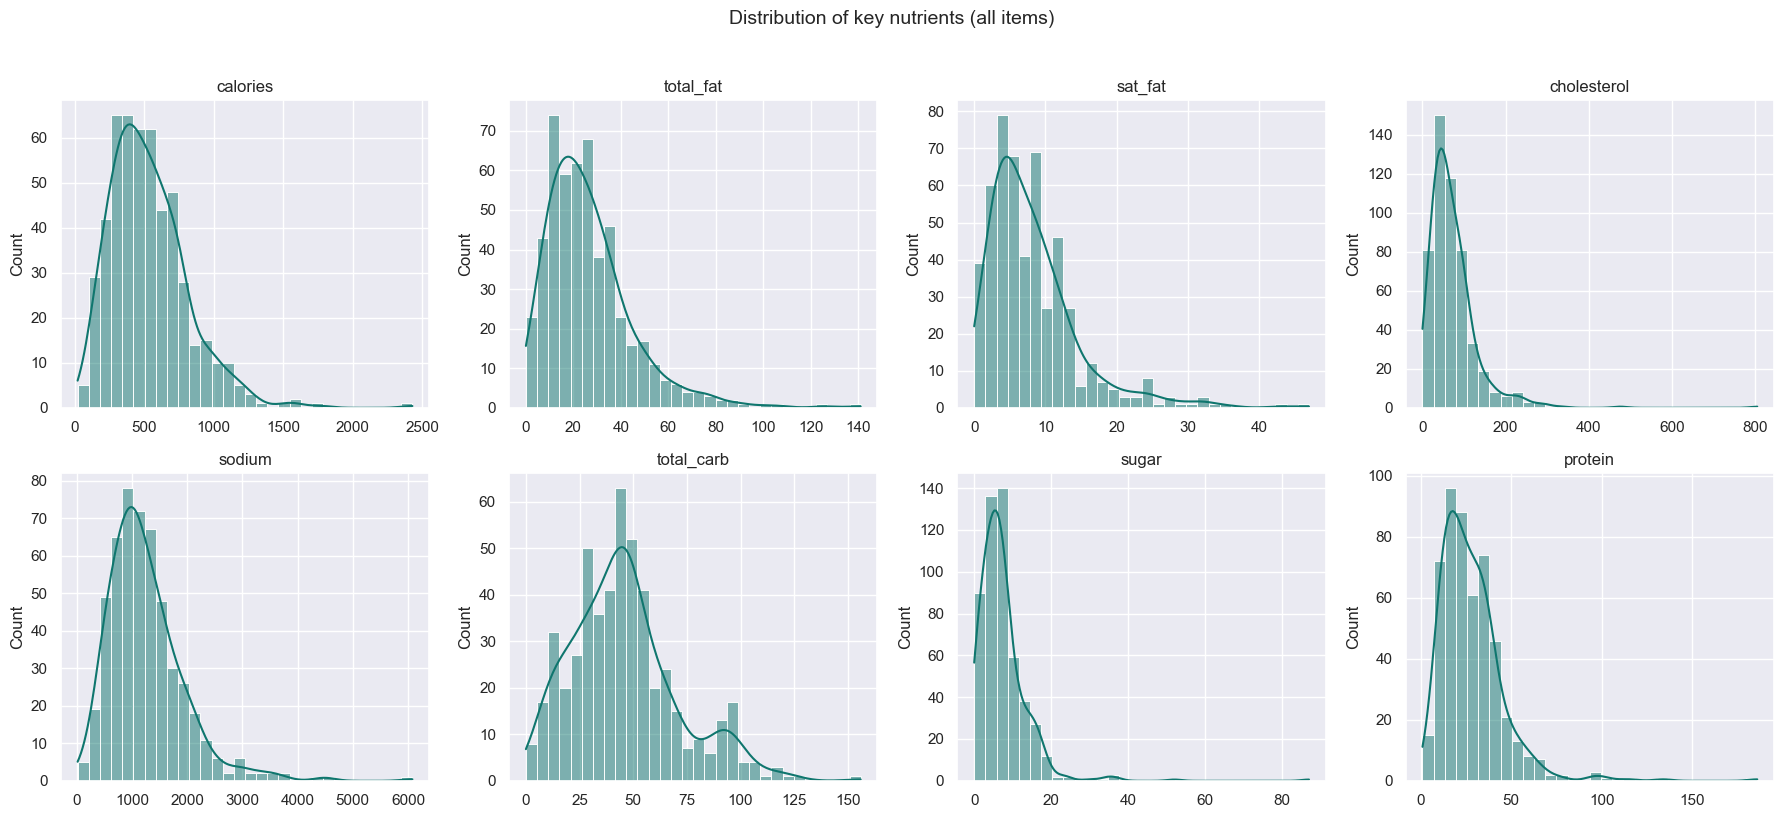

In [9]:
main_cols = ["calories","total_fat","sat_fat","cholesterol","sodium","total_carb","sugar","protein"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), main_cols):
    sns.histplot(df[c].dropna(), bins=30, kde=True, ax=ax, color="#0F766E")
    ax.set_title(c)
    ax.set_xlabel("")
plt.suptitle("Distribution of key nutrients (all items)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

### 3.5 Outliers by restaurant

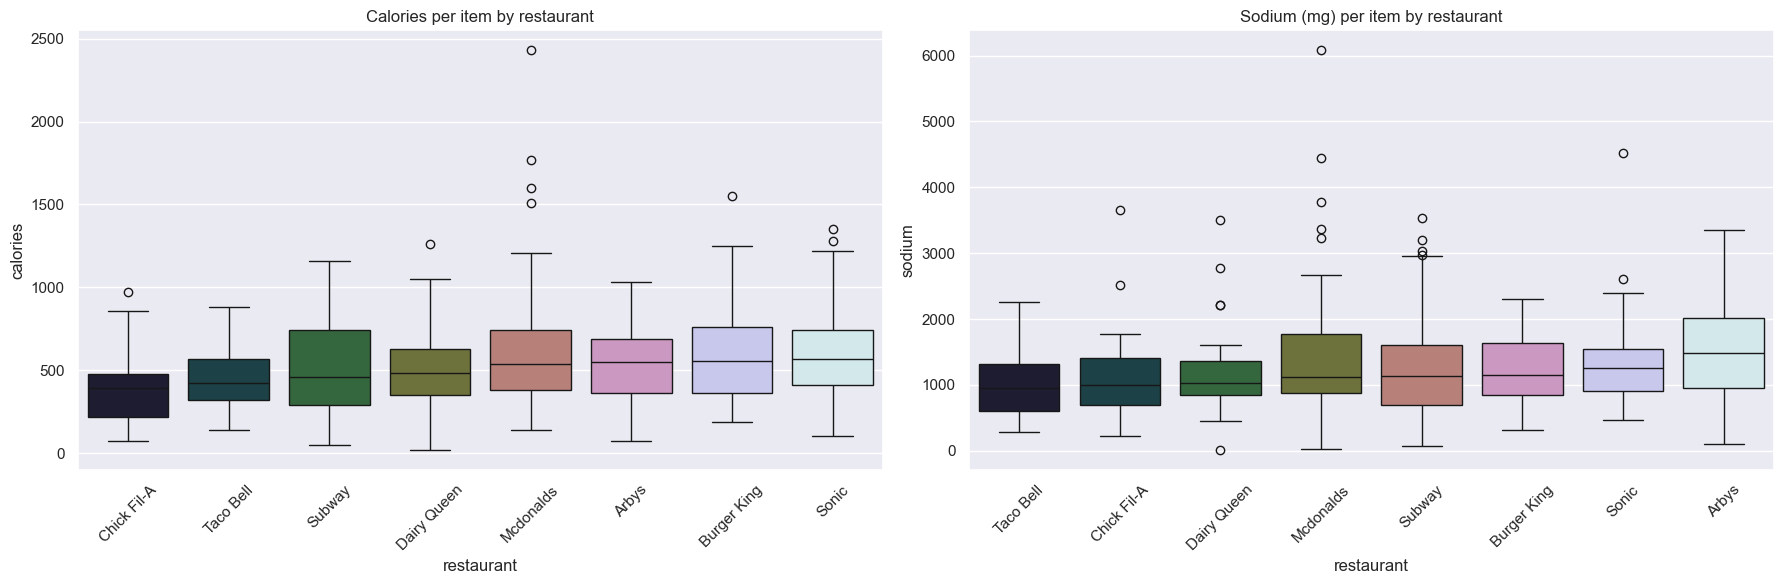

Calorie outliers (IQR rule): 9 items. These are real menu items (e.g. large combos), so they are kept.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
order = df.groupby("restaurant")["calories"].median().sort_values().index
sns.boxplot(data=df, x="restaurant", y="calories", order=order, ax=axes[0], palette="cubehelix")
axes[0].set_title("Calories per item by restaurant"); axes[0].tick_params(axis="x", rotation=45)
order = df.groupby("restaurant")["sodium"].median().sort_values().index
sns.boxplot(data=df, x="restaurant", y="sodium", order=order, ax=axes[1], palette="cubehelix")
axes[1].set_title("Sodium (mg) per item by restaurant"); axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

# IQR-based outlier counts for calories
q1, q3 = df["calories"].quantile([.25, .75]); iqr = q3 - q1
out = df[(df["calories"] > q3 + 1.5*iqr) | (df["calories"] < q1 - 1.5*iqr)]
print(f"Calorie outliers (IQR rule): {len(out)} items. These are real menu items (e.g. large combos), so they are kept.")

### 3.6 Correlations

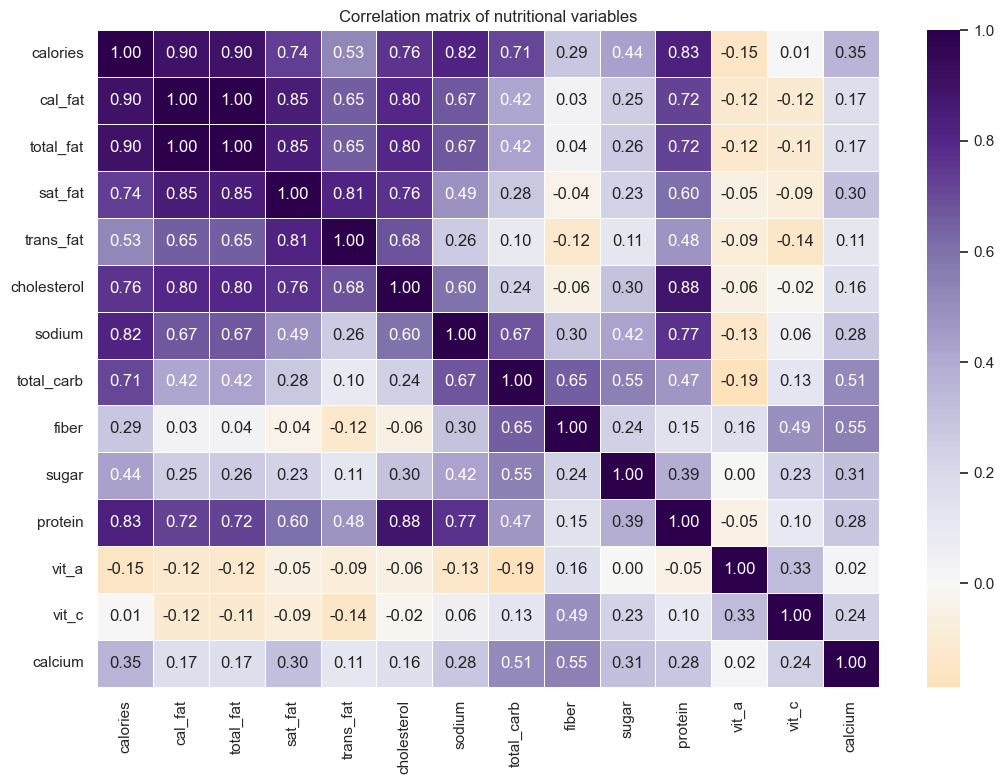

In [11]:
plt.figure(figsize=(11, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="PuOr", center=0, linewidths=.5)
plt.title("Correlation matrix of nutritional variables")
plt.tight_layout(); plt.show()

## 4. Answering the questions

### Q1. Which restaurant has the highest number of food items?

,number_of_items
restaurant,
Taco Bell,113
Subway,96
Burger King,70
Mcdonalds,57
Arbys,55
Sonic,53
Dairy Queen,42
Chick Fil-A,27


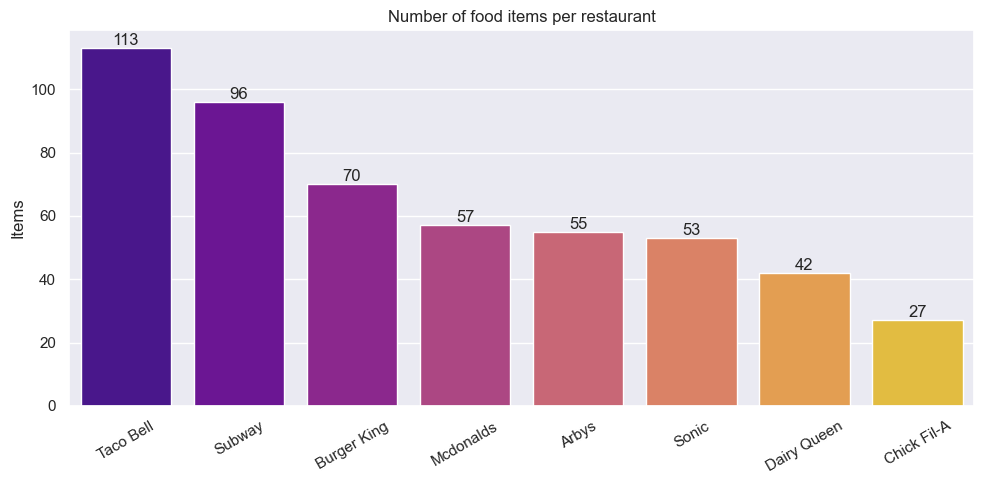

ANSWER: Taco Bell has the most items (113 of 513).


In [12]:
item_counts = df["restaurant"].value_counts()
top_rest = item_counts.idxmax()
display(item_counts.to_frame("number_of_items"))

plt.figure(figsize=(10, 5))
sns.barplot(x=item_counts.index, y=item_counts.values, palette="plasma")
plt.title("Number of food items per restaurant"); plt.ylabel("Items"); plt.xlabel("")
plt.xticks(rotation=30)
for i, v in enumerate(item_counts.values): plt.text(i, v + 1, v, ha="center")
plt.tight_layout(); plt.show()

answers["Q1"] = f"{top_rest} has the most items ({item_counts.max()} of {len(df)})."
print("ANSWER:", answers["Q1"])

### Q2. Top 10 food items with the highest calories

,restaurant,item,calories,total_fat,sodium
1,Mcdonalds,20 piece Buttermilk Crispy Chicken Tenders,2430,141,6080
2,Mcdonalds,40 piece Chicken McNuggets,1770,107,3370
3,Mcdonalds,10 piece Sweet N' Spicy Honey BBQ Glazed Tenders,1600,66,4450
4,Burger King,American Brewhouse King,1550,126,1820
5,Mcdonalds,12 piece Buttermilk Crispy Chicken Tenders,1510,88,3770
6,Sonic,Garlic Parmesan Dunked Ultimate Chicken Sandwich,1350,100,2180
7,Sonic,Super Sonic Bacon Double Cheeseburger (w/mayo),1280,92,1630
8,Dairy Queen,6 Piece Chicken Strip Basket w/ Country Gravy,1260,66,3500
9,Burger King,Rodeo King,1250,82,2270
10,Sonic,Super Sonic Double Cheeseburger W/ Mayo,1220,87,1520


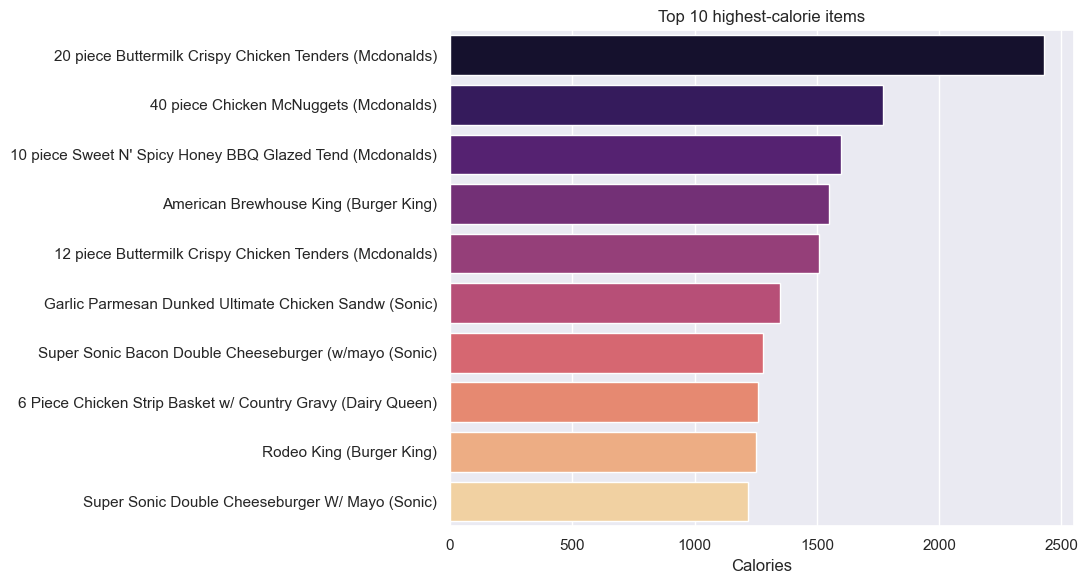

ANSWER: Highest-calorie item: 20 piece Buttermilk Crispy Chicken Tenders (Mcdonalds, 2,430 kcal). Restaurants in the top 10: Mcdonalds, Sonic, Burger King, Dairy Queen.


In [13]:
top10_cal = (df.nlargest(10, "calories")[["restaurant","item","calories","total_fat","sodium"]]
             .reset_index(drop=True))
top10_cal.index += 1
display(top10_cal)

plt.figure(figsize=(11, 6))
labels = top10_cal["item"].str.slice(0, 45) + " (" + top10_cal["restaurant"] + ")"
sns.barplot(y=labels, x=top10_cal["calories"], palette="magma")
plt.title("Top 10 highest-calorie items"); plt.xlabel("Calories"); plt.ylabel("")
plt.tight_layout(); plt.show()

answers["Q2"] = ("Highest-calorie item: " + f"{top10_cal.iloc[0]['item']} ({top10_cal.iloc[0]['restaurant']}, "
                 f"{top10_cal.iloc[0]['calories']:,.0f} kcal). Restaurants in the top 10: "
                 + ", ".join(top10_cal['restaurant'].value_counts().index) + ".")
print("ANSWER:", answers["Q2"])

### Q3. Average calorie count of items for each restaurant

,mean,median,items
restaurant,,,
Mcdonalds,640.35,540.00,57
Sonic,631.70,570.00,53
Burger King,608.57,555.00,70
Arbys,532.73,550.00,55
Dairy Queen,520.24,485.00,42
Subway,503.02,460.00,96
Taco Bell,443.01,420.00,113
Chick Fil-A,384.44,390.00,27


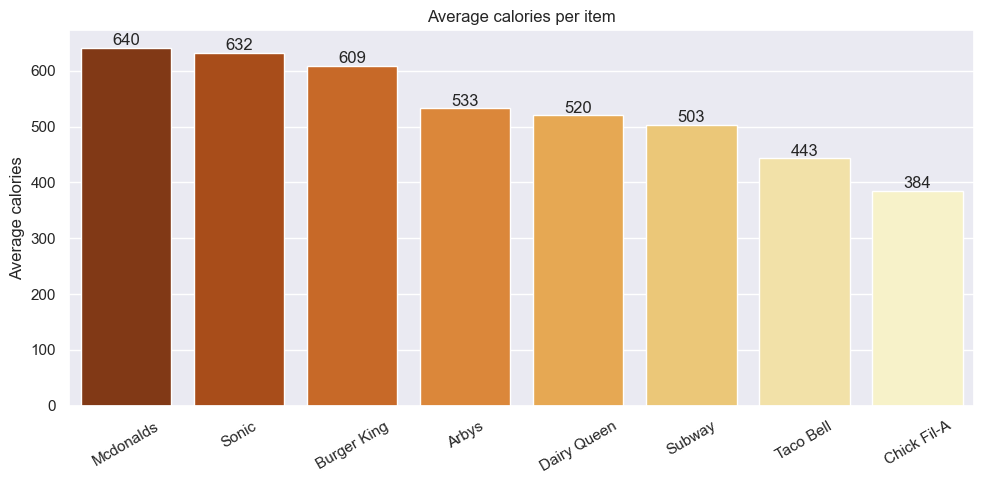

ANSWER: Average calories per item: Mcdonalds: 640; Sonic: 632; Burger King: 609; Arbys: 533; Dairy Queen: 520; Subway: 503; Taco Bell: 443; Chick Fil-A: 384.


In [14]:
avg_cal = df.groupby("restaurant")["calories"].agg(mean="mean", median="median", items="count").sort_values("mean", ascending=False)
display(avg_cal)

plt.figure(figsize=(10, 5))
sns.barplot(x=avg_cal.index, y=avg_cal["mean"], palette="YlOrBr_r")
plt.title("Average calories per item"); plt.ylabel("Average calories"); plt.xlabel("")
plt.xticks(rotation=30)
for i, v in enumerate(avg_cal["mean"]): plt.text(i, v + 5, f"{v:,.0f}", ha="center")
plt.tight_layout(); plt.show()

answers["Q3"] = ("Average calories per item: " + "; ".join(f"{r}: {v:,.0f}" for r, v in avg_cal["mean"].items()) + ".")
print("ANSWER:", answers["Q3"])

### Q4. Which restaurant offers items with the highest average protein?

,mean,median
restaurant,,
Mcdonalds,40.30,33.00
Chick Fil-A,31.70,29.00
Subway,30.31,26.00
Burger King,30.01,29.00
Arbys,29.25,29.00
Sonic,29.19,30.00
Dairy Queen,24.83,23.00
Taco Bell,17.38,16.00


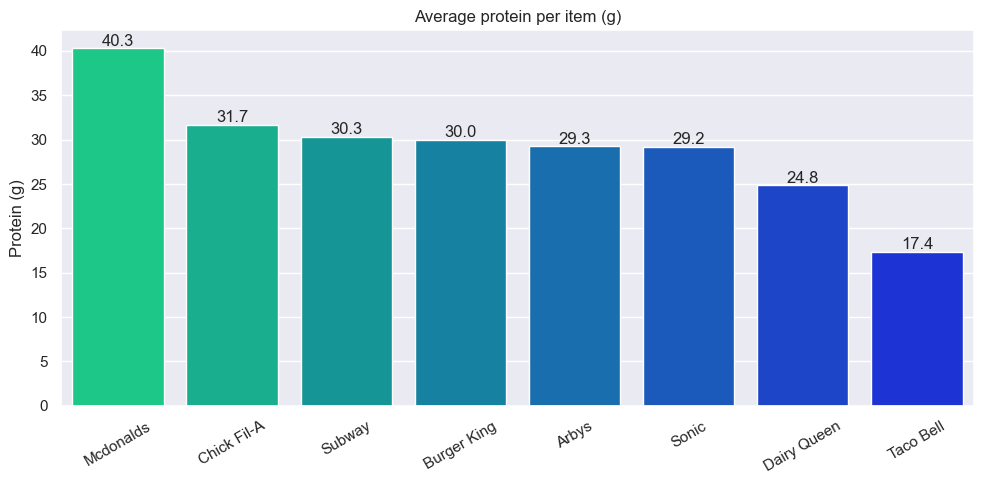

ANSWER: Mcdonalds has the highest average protein (40.3 g per item).


In [15]:
avg_prot = df.groupby("restaurant")["protein"].agg(mean="mean", median="median").sort_values("mean", ascending=False)
display(avg_prot)

plt.figure(figsize=(10, 5))
sns.barplot(x=avg_prot.index, y=avg_prot["mean"], palette="winter_r")
plt.title("Average protein per item (g)"); plt.ylabel("Protein (g)"); plt.xlabel("")
plt.xticks(rotation=30)
for i, v in enumerate(avg_prot["mean"]): plt.text(i, v + .3, f"{v:,.1f}", ha="center")
plt.tight_layout(); plt.show()

answers["Q4"] = f"{avg_prot.index[0]} has the highest average protein ({avg_prot['mean'].iloc[0]:.1f} g per item)."
print("ANSWER:", answers["Q4"])

### Q5. Highest and lowest average total fat

,avg_total_fat_g
restaurant,
Sonic,37.64
Burger King,36.81
Mcdonalds,31.81
Dairy Queen,28.86
Arbys,26.98
Taco Bell,20.86
Subway,18.48
Chick Fil-A,16.15


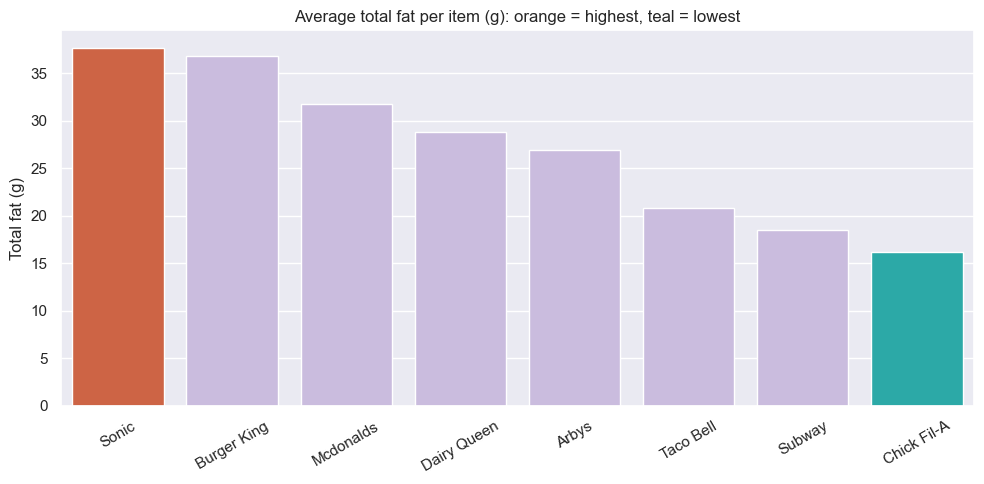

ANSWER: Highest average total fat: Sonic (37.6 g). Lowest: Chick Fil-A (16.1 g).


In [16]:
avg_fat = df.groupby("restaurant")["total_fat"].mean().sort_values(ascending=False)
display(avg_fat.to_frame("avg_total_fat_g"))

colors = ["#E4572E" if r == avg_fat.index[0] else "#17BEBB" if r == avg_fat.index[-1] else "#C9B6E4" for r in avg_fat.index]
plt.figure(figsize=(10, 5))
sns.barplot(x=avg_fat.index, y=avg_fat.values, palette=colors)
plt.title("Average total fat per item (g): orange = highest, teal = lowest")
plt.ylabel("Total fat (g)"); plt.xlabel(""); plt.xticks(rotation=30)
plt.tight_layout(); plt.show()

answers["Q5"] = (f"Highest average total fat: {avg_fat.index[0]} ({avg_fat.iloc[0]:.1f} g). "
                 f"Lowest: {avg_fat.index[-1]} ({avg_fat.iloc[-1]:.1f} g).")
print("ANSWER:", answers["Q5"])

### Q6. Items with the highest sugar and their calories

,restaurant,item,sugar,calories
1,Mcdonalds,10 piece Sweet N' Spicy Honey BBQ Glazed Tenders,87,1600
2,Mcdonalds,6 piece Sweet N' Spicy Honey BBQ Glazed Tenders,52,960
3,Burger King,"Chicken, Apple & Cranberry Salad w/ Crispy Chi...",37,700
4,Subway,Footlong Sweet Onion Chicken Teriyaki,36,760
5,Mcdonalds,4 piece Sweet N' Spicy Honey BBQ Glazed Tenders,35,640
6,Burger King,"Chicken, Apple & Cranberry Salad w/ Grilled Ch...",34,560
7,Dairy Queen,Large Cheese Curds,30,1050
8,Subway,Footlong Corned Beef Reuben,24,940
9,Subway,Footlong Meatball Marinara,24,960
10,Arbys,Arby-Q Sandwich,23,400


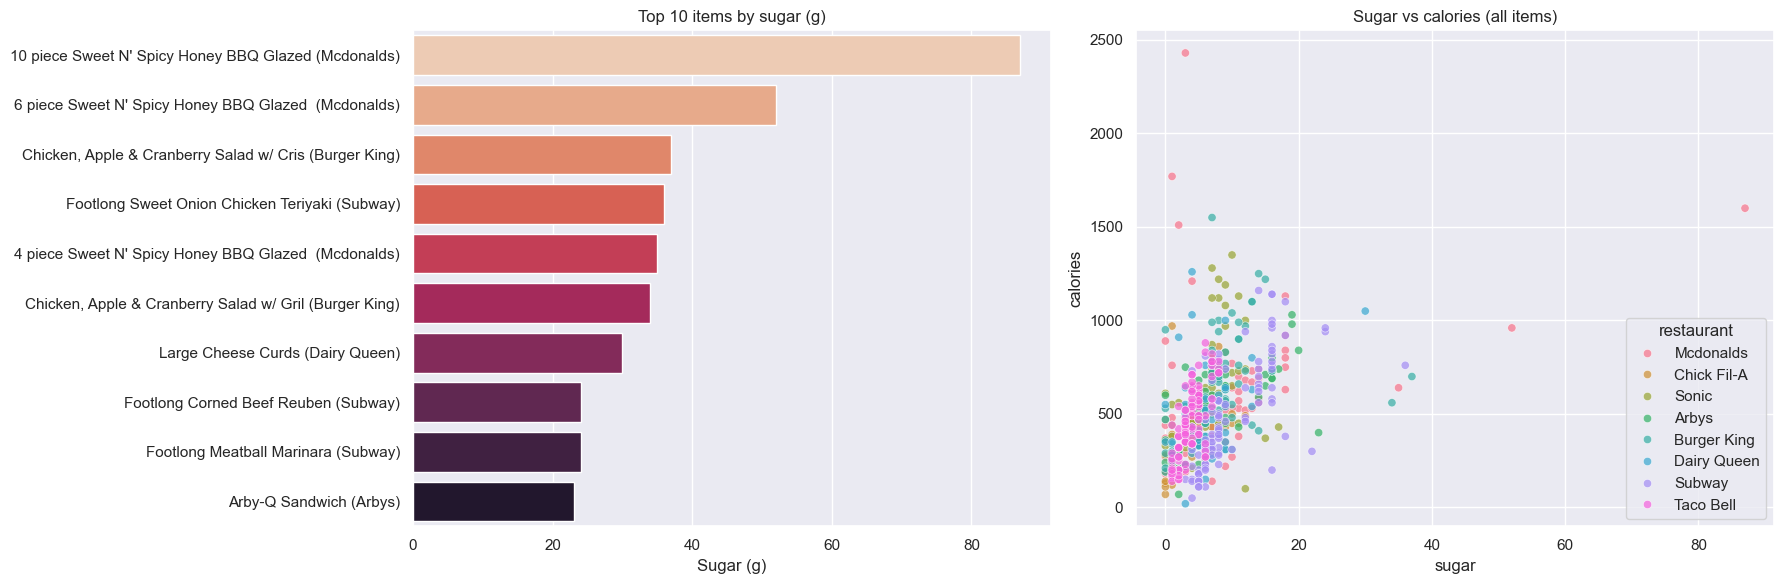

ANSWER: Highest sugar: 10 piece Sweet N' Spicy Honey BBQ Glazed Tenders (Mcdonalds) with 87 g sugar and 1,600 kcal. Top-10 sugar items average 857 kcal (dataset mean 531); sugar-calorie correlation r = 0.44.


In [17]:
top_sugar = (df.nlargest(10, "sugar")[["restaurant","item","sugar","calories"]].reset_index(drop=True))
top_sugar.index += 1
display(top_sugar)

fig, ax = plt.subplots(1, 2, figsize=(18, 6))
labels = top_sugar["item"].str.slice(0, 40) + " (" + top_sugar["restaurant"] + ")"
sns.barplot(y=labels, x=top_sugar["sugar"], palette="rocket_r", ax=ax[0])
ax[0].set_title("Top 10 items by sugar (g)"); ax[0].set_ylabel(""); ax[0].set_xlabel("Sugar (g)")
sns.scatterplot(data=df, x="sugar", y="calories", hue="restaurant", alpha=.7, ax=ax[1])
ax[1].set_title("Sugar vs calories (all items)")
plt.tight_layout(); plt.show()

corr = df["sugar"].corr(df["calories"])
answers["Q6"] = (f"Highest sugar: {top_sugar.iloc[0]['item']} ({top_sugar.iloc[0]['restaurant']}) with "
                 f"{top_sugar.iloc[0]['sugar']:.0f} g sugar and {top_sugar.iloc[0]['calories']:,.0f} kcal. "
                 f"Top-10 sugar items average {top_sugar['calories'].mean():,.0f} kcal "
                 f"(dataset mean {df['calories'].mean():,.0f}); sugar-calorie correlation r = {corr:.2f}.")
print("ANSWER:", answers["Q6"])

### Q7. Effect of food type (Salad vs Other) on calories, fat, carbs and protein

,calories,total_fat,total_carb,protein,items
food_type,,,,,
Other,554.44,27.47,48.76,28.63,450
Salad,364.44,20.41,23.41,22.90,63


,Salad vs Other (%)
calories,-34.27
total_fat,-25.69
total_carb,-51.98
protein,-19.99


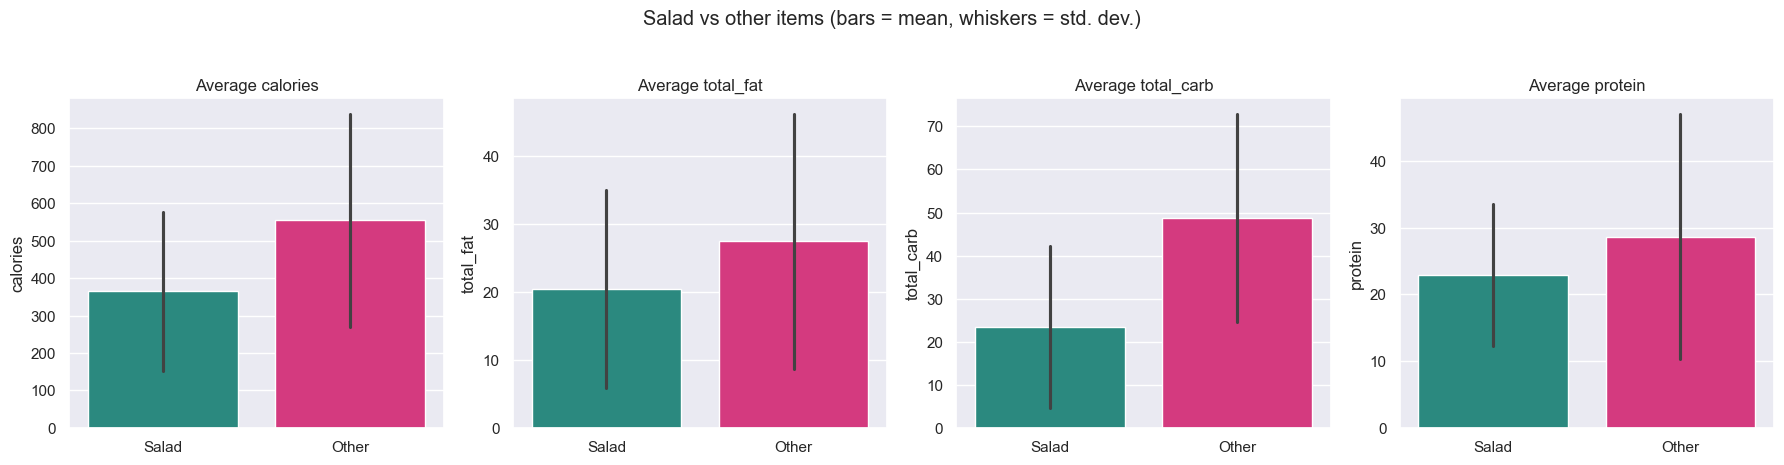

calories     Welch t =  -6.33, p = 8e-09
total_fat    Welch t =  -3.46, p = 0.00082
total_carb   Welch t =  -9.68, p = 9.1e-16
protein      Welch t =  -3.57, p = 0.00051

ANSWER: Salads vs other items (average change): calories -34%, total_fat -26%, total_carb -52%, protein -20%.


In [18]:
cols7 = ["calories","total_fat","total_carb","protein"]
type_summary = df.groupby("food_type")[cols7].mean()
type_summary["items"] = df.groupby("food_type").size()
display(type_summary)

diff_pct = (type_summary.loc["Salad", cols7] / type_summary.loc["Other", cols7] - 1) * 100
display(diff_pct.to_frame("Salad vs Other (%)"))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, c in zip(axes, cols7):
    sns.barplot(data=df, x="food_type", y=c, order=["Salad","Other"], palette=["#1B998B","#ED217C"], errorbar="sd", ax=ax)
    ax.set_title(f"Average {c}"); ax.set_xlabel("")
plt.suptitle("Salad vs other items (bars = mean, whiskers = std. dev.)", y=1.03)
plt.tight_layout(); plt.show()

# Is the difference statistically meaningful? Welch t-test
from scipy import stats
for c in cols7:
    t, p = stats.ttest_ind(df.loc[df.food_type=="Salad", c].dropna(), df.loc[df.food_type=="Other", c].dropna(), equal_var=False)
    print(f"{c:12s} Welch t = {t:6.2f}, p = {p:.2g}")

answers["Q7"] = ("Salads vs other items (average change): " +
                 ", ".join(f"{c} {d:+.0f}%" for c, d in diff_pct.items()) + ".")
print("\nANSWER:", answers["Q7"])

### Q8. Which restaurant offers the best combination of low calories and high protein? Use the available nutritional information to support your answer.

,avg_calories,avg_protein_g,protein_per_100kcal,pct_lean_protein_items,balance_score
restaurant,,,,,
Chick Fil-A,384.44,31.70,8.25,33.33,87.50
Subway,503.02,30.31,6.03,18.75,52.91
Mcdonalds,640.35,40.30,6.29,12.28,51.61
Arbys,532.73,29.25,5.49,5.45,43.38
Dairy Queen,520.24,24.83,4.77,11.90,33.04
Burger King,599.71,30.01,5.00,2.90,32.01
Taco Bell,443.01,17.38,3.92,0.00,25.70
Sonic,631.70,29.19,4.62,7.55,23.68


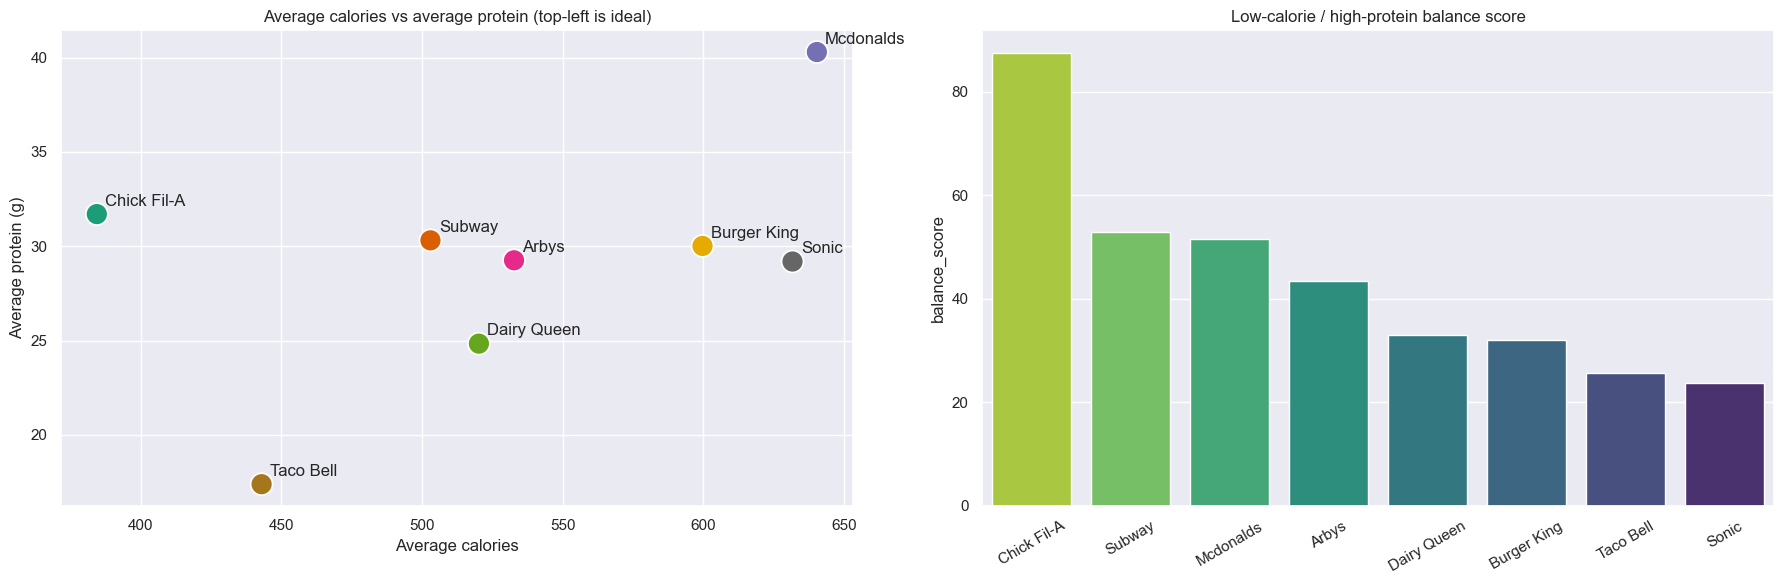

ANSWER: Chick Fil-A offers the best low-calorie/high-protein combination: balance score 87/100, 8.2 g protein per 100 kcal, avg 384 kcal and 31.7 g protein, with 33% of its menu being lean-protein items. Best raw protein density: Chick Fil-A.


In [19]:
d8 = df.dropna(subset=["protein", "calories"])
g = d8.groupby("restaurant")
r8 = pd.DataFrame({
    "avg_calories": g["calories"].mean(),
    "avg_protein_g": g["protein"].mean(),
    "protein_per_100kcal": g["protein"].sum() / g["calories"].sum() * 100,
    "pct_lean_protein_items": g.apply(lambda x: ((x["protein"] >= 20) & (x["calories"] <= 400)).mean() * 100),
})

def minmax(s): return (s - s.min()) / (s.max() - s.min())
r8["balance_score"] = (minmax(r8["avg_protein_g"]) + minmax(r8["protein_per_100kcal"]) + (1 - minmax(r8["avg_calories"]))) / 3 * 100
r8 = r8.sort_values("balance_score", ascending=False)
display(r8)

fig, ax = plt.subplots(1, 2, figsize=(18, 6))
sns.scatterplot(data=r8, x="avg_calories", y="avg_protein_g", s=250, hue=r8.index, legend=False, ax=ax[0], palette="Dark2")
for name, row in r8.iterrows():
    ax[0].annotate(name, (row["avg_calories"], row["avg_protein_g"]), xytext=(6, 6), textcoords="offset points")
ax[0].set_title("Average calories vs average protein (top-left is ideal)")
ax[0].set_xlabel("Average calories"); ax[0].set_ylabel("Average protein (g)")
sns.barplot(x=r8.index, y=r8["balance_score"], palette="viridis_r", ax=ax[1])
ax[1].set_title("Low-calorie / high-protein balance score"); ax[1].set_xlabel(""); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

best8 = r8.index[0]
answers["Q8"] = (f"{best8} offers the best low-calorie/high-protein combination: balance score {r8.loc[best8,'balance_score']:.0f}/100, "
                 f"{r8.loc[best8,'protein_per_100kcal']:.1f} g protein per 100 kcal, avg {r8.loc[best8,'avg_calories']:,.0f} kcal and "
                 f"{r8.loc[best8,'avg_protein_g']:.1f} g protein, with {r8.loc[best8,'pct_lean_protein_items']:.0f}% of its menu being lean-protein items. "
                 f"Best raw protein density: {r8['protein_per_100kcal'].idxmax()}.")
print("ANSWER:", answers["Q8"])

### Q9.  Can you identify the 10 least healthy food items by creating a Health Risk Score using calories, total fat, saturated fat, trans fat, cholesterol, and sodium?

,restaurant,item,calories,total_fat,sat_fat,trans_fat,cholesterol,sodium,health_risk_score
1,Burger King,American Brewhouse King,1550,126,47.00,8.00,805,1820,197.27
2,Mcdonalds,20 piece Buttermilk Crispy Chicken Tenders,2430,141,24.00,2.00,475,6080,159.04
3,Sonic,Super Sonic Bacon Double Cheeseburger (w/mayo),1280,92,36.00,4.00,260,1630,125.13
4,Sonic,Super Sonic Double Cheeseburger W/ Mayo,1220,87,34.00,4.00,245,1520,119.76
5,Burger King,Rodeo King,1250,82,31.00,3.50,230,2270,117.55
6,Sonic,Super Sonic Jalapeno Double Cheeseburger,1120,76,32.00,4.00,235,1690,115.54
7,Sonic,Super Sonic Double Cheeseburger W/ Ketchup,1130,76,32.00,4.00,235,1620,115.01
8,Sonic,Super Sonic Double Cheeseburger W/ Mustard,1120,76,32.00,4.00,235,1550,114.33
9,Burger King,Farmhouse King,1220,80,28.00,3.00,335,2050,111.03
10,Dairy Queen,Large Cheese Curds,1050,75,43.00,1.00,180,2210,108.77


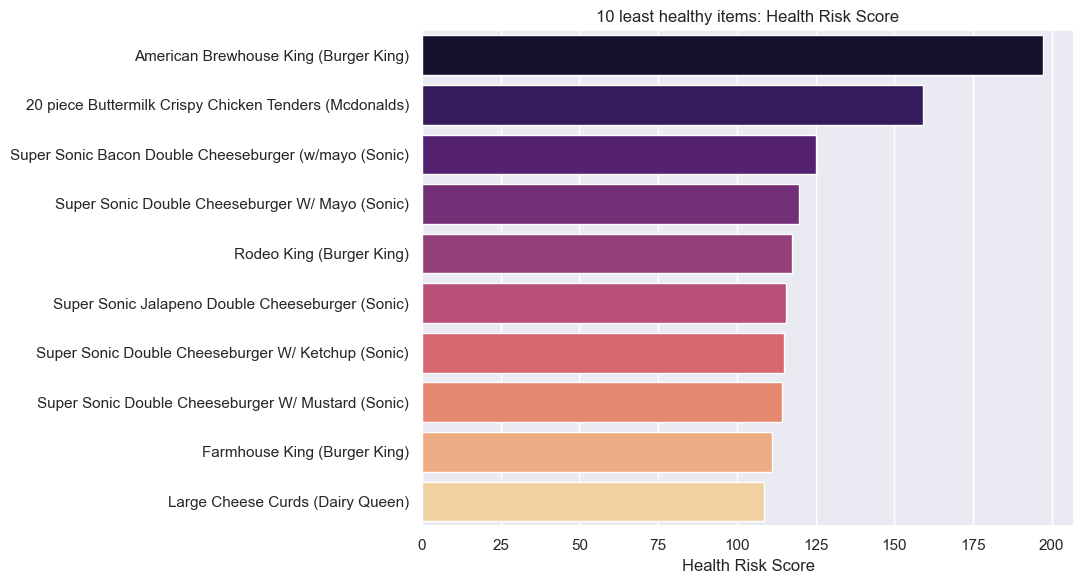

Overlap between reference-limit and min-max versions of the top 10: 9/10
ANSWER: Least healthy item: American Brewhouse King (Burger King, score 197). The top-10 list is dominated by: Sonic, Burger King, Mcdonalds. Robustness check overlap: 9/10.


In [20]:
risk_ref = {"calories": 2000, "total_fat": 78, "sat_fat": 20, "trans_fat": 2, "cholesterol": 300, "sodium": 2300}
risk_w   = {"calories": .15, "total_fat": .15, "sat_fat": .25, "trans_fat": .15, "cholesterol": .10, "sodium": .20}
assert abs(sum(risk_w.values()) - 1) < 1e-9

d9 = df.dropna(subset=list(risk_ref)).copy()
for k, ref in risk_ref.items():
    d9[f"{k}_pctref"] = d9[k] / ref * 100
d9["health_risk_score"] = sum(d9[f"{k}_pctref"] * w for k, w in risk_w.items())

worst10 = d9.nlargest(10, "health_risk_score")[["restaurant","item","calories","total_fat","sat_fat","trans_fat","cholesterol","sodium","health_risk_score"]].reset_index(drop=True)
worst10.index += 1
display(worst10)

plt.figure(figsize=(11, 6))
labels = worst10["item"].str.slice(0, 45) + " (" + worst10["restaurant"] + ")"
sns.barplot(y=labels, x=worst10["health_risk_score"], palette="magma")
plt.title("10 least healthy items: Health Risk Score"); plt.xlabel("Health Risk Score"); plt.ylabel("")
plt.tight_layout(); plt.show()

# Robustness: alternative min-max scoring with the same weights
alt = sum(minmax(d9[k]) * w for k, w in risk_w.items())
alt_top = set(d9.loc[alt.nlargest(10).index, "item"] + d9.loc[alt.nlargest(10).index, "restaurant"])
base_top = set(worst10["item"] + worst10["restaurant"])
print(f"Overlap between reference-limit and min-max versions of the top 10: {len(alt_top & base_top)}/10")

answers["Q9"] = (f"Least healthy item: {worst10.iloc[0]['item']} ({worst10.iloc[0]['restaurant']}, score {worst10.iloc[0]['health_risk_score']:.0f}). "
                 f"The top-10 list is dominated by: {', '.join(worst10['restaurant'].value_counts().index[:3])}. "
                 f"Robustness check overlap: {len(alt_top & base_top)}/10.")
print("ANSWER:", answers["Q9"])

### Q10. Can you compare the nutritional profiles of all restaurants and determine which restaurant provides the healthiest overall menu? Create your own scoring system using calories, fat, sugar, sodium, fiber, protein, and vitamins, and justify your ranking?

,calories,total_fat,sugar,sodium,fiber,protein,vitamins
restaurant,,,,,,,
Chick Fil-A,384.44,16.15,4.15,"1,151.48",2.32,31.70,13.05
Taco Bell,443.01,20.86,3.69,"1,012.39",5.70,17.38,13.73
Subway,503.02,18.48,10.09,"1,272.97",6.56,30.31,34.49
Dairy Queen,520.24,28.86,6.36,"1,181.79",2.83,24.83,11.59
Arbys,532.73,26.98,7.56,"1,515.27",2.71,29.25,12.77
Burger King,608.57,36.81,8.19,"1,223.57",2.38,30.01,NaN
Sonic,631.70,37.64,6.53,"1,350.75",2.66,29.19,9.98
Mcdonalds,640.35,31.81,11.07,"1,437.89",3.23,40.30,24.20


,calories,total_fat,sugar,sodium,fiber,protein,vitamins,HEALTH_SCORE
restaurant,,,,,,,,
Subway,54.00,89.00,13.00,48.00,100.00,56.00,100.00,68.40
Taco Bell,77.00,78.00,100.00,100.00,80.00,0.00,15.00,62.50
Chick Fil-A,100.00,100.00,94.00,72.00,0.00,62.00,13.00,61.50
Dairy Queen,47.00,41.00,64.00,66.00,12.00,33.00,7.00,37.20
Mcdonalds,0.00,27.00,0.00,15.00,21.00,100.00,58.00,33.30
Arbys,42.00,50.00,48.00,0.00,9.00,52.00,11.00,29.40
Burger King,12.00,4.00,39.00,58.00,1.00,55.00,NaN,27.70
Sonic,3.00,0.00,62.00,33.00,8.00,52.00,0.00,20.50


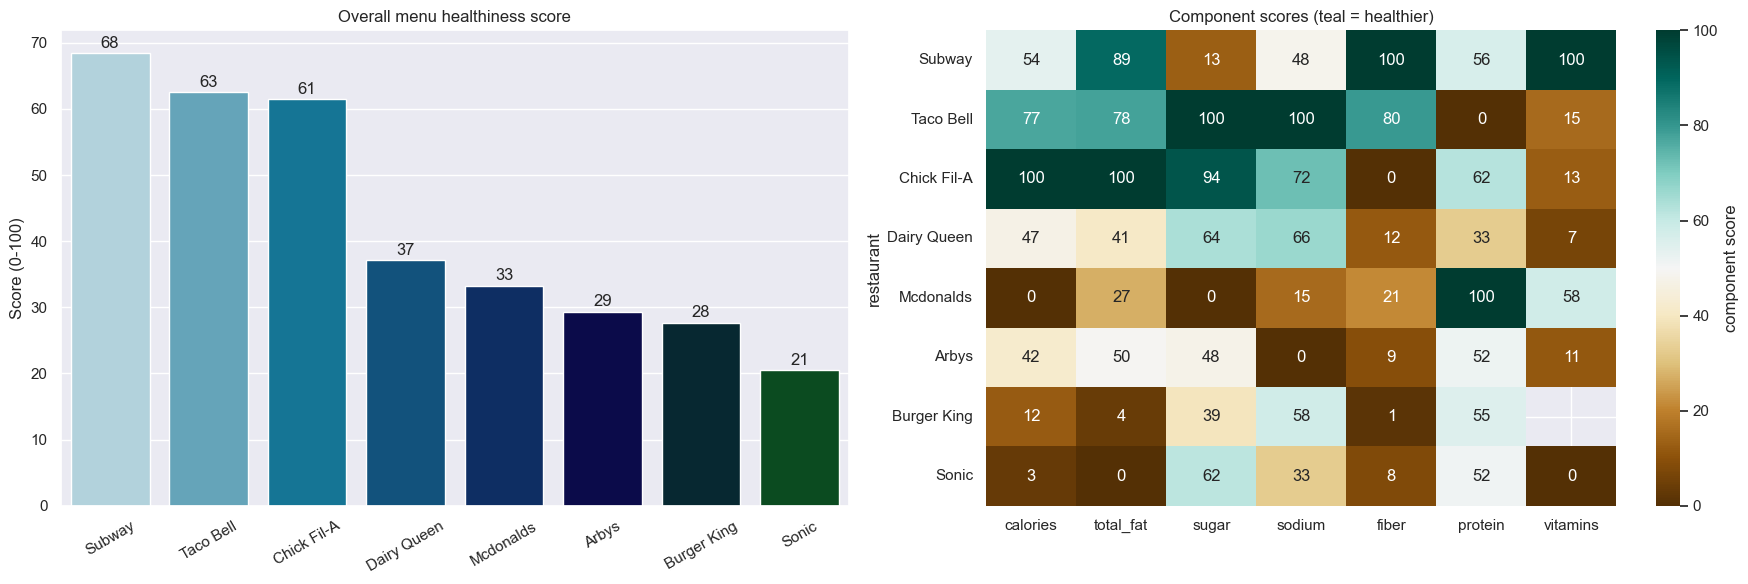

,base,equal weights,heart-health focus
restaurant,,,
Subway,1,1,2
Taco Bell,2,2,1
Chick Fil-A,3,3,3
Dairy Queen,4,4,4
Mcdonalds,5,5,6
Arbys,6,6,7
Burger King,7,7,5
Sonic,8,8,8


ANSWER: Subway has the healthiest overall menu (score 68/100); ranking: Subway (68) > Taco Bell (63) > Chick Fil-A (61) > Dairy Queen (37) > Mcdonalds (33) > Arbys (29) > Burger King (28) > Sonic (21). Winner by alternative weightings: equal weights: Subway, heart-health focus: Taco Bell.


In [21]:
df["vitamins"] = df[["vit_a", "vit_c", "calcium"]].mean(axis=1)   # item-level mean of available vitamin %DV

comp = df.groupby("restaurant")[["calories","total_fat","sugar","sodium","fiber","protein","vitamins"]].mean()
display(comp.sort_values("calories"))

direction = {"calories": -1, "total_fat": -1, "sugar": -1, "sodium": -1, "fiber": 1, "protein": 1, "vitamins": 1}
weights   = pd.Series({"calories": .15, "total_fat": .15, "sugar": .10, "sodium": .15, "fiber": .15, "protein": .15, "vitamins": .15})

# 0-1 "goodness" for each component
S = pd.DataFrame({c: (minmax(comp[c]) if direction[c] == 1 else 1 - minmax(comp[c])) for c in comp})

def weighted_score(S, w):
    mask = S.notna()
    return (S.fillna(0) * w).sum(axis=1) / (mask * w).sum(axis=1) * 100

final = weighted_score(S, weights).sort_values(ascending=False)
rank_tbl = S.loc[final.index].mul(100).round(0)
rank_tbl["HEALTH_SCORE"] = final.round(1)
display(rank_tbl)

fig, ax = plt.subplots(1, 2, figsize=(18, 6))
sns.barplot(x=final.index, y=final.values, palette="ocean_r", ax=ax[0])
ax[0].set_title("Overall menu healthiness score"); ax[0].set_ylabel("Score (0-100)"); ax[0].set_xlabel("")
ax[0].tick_params(axis="x", rotation=30)
for i, v in enumerate(final.values): ax[0].text(i, v + .8, f"{v:.0f}", ha="center")
sns.heatmap(S.loc[final.index].mul(100), annot=True, fmt=".0f", cmap="BrBG", vmin=0, vmax=100, ax=ax[1], cbar_kws={"label": "component score"})
ax[1].set_title("Component scores (teal = healthier)")
plt.tight_layout(); plt.show()

# Sensitivity: equal weights and a "heart-health" weighting
alt_weights = {
    "equal weights": pd.Series(1/7, index=weights.index),
    "heart-health focus": pd.Series({"calories": .10, "total_fat": .20, "sugar": .10, "sodium": .25, "fiber": .15, "protein": .10, "vitamins": .10}),
}
sens = pd.DataFrame({"base": final.rank(ascending=False)})
for name, w in alt_weights.items():
    sens[name] = weighted_score(S, w).rank(ascending=False)
display(sens.sort_values("base").astype(int))

winner = final.index[0]
answers["Q10"] = (f"{winner} has the healthiest overall menu (score {final.iloc[0]:.0f}/100); ranking: " +
                  " > ".join(f"{r} ({v:.0f})" for r, v in final.items()) + ". "
                  f"Winner by alternative weightings: " + ", ".join(f"{n}: {weighted_score(S, w).idxmax()}" for n, w in alt_weights.items()) + ".")
print("ANSWER:", answers["Q10"])